In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *


In [2]:
#!ls /bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRp/spin2/work/monthly/TT*

In [7]:
domain='GRc';domainM='GRq';spin='spin2';var='PRE';units='mm/month';
nx=10;ny=10
iyr=1980;fyr=2015
sourceData=f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domain}/spin2/work/monthly/'
model1='MAR'
ds_RF_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'+
                            'RF_mon_MARv3.14_ER5_spin2_'+domainM+'_1950-2024.nc')['RF']
ds_RF = ds_RF_raw.rename({'TIME': 'time'})
###
ds_SF_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'+
                            'SF_mon_MARv3.14_ER5_spin2_'+domainM+'_1950-2024.nc')['SF']
ds_SF = ds_SF_raw.rename({'TIME': 'time'})
ds_TF=ds_RF+ds_SF

ds1=ds_TF[:,ny:-ny,nx:-nx].sel(time=slice(str(iyr), str(fyr)))
field1=ds1

ds_grM= xr.open_dataset(f'/home/santolam/NST.2000.01.01.00.{domain}.nc')
LONS=ds_grM.LON[ny:-ny,nx:-nx].values
LATS=ds_grM.LAT[ny:-ny,nx:-nx].values
dsSH=ds_grM.SH[ny:-ny,nx:-nx]
dsICE=ds_grM.ICE[ny:-ny,nx:-nx]

latS=LATS.min(); latN=LATS.max()
lonW=LONS.min(); lonE=LONS.max()

rmon_List=[1,2,3,4,5,6,7,8,9,10,11,12]
vals_List=[]; #anoms_List=[];anoms_detrend_List=[]
for rmon in rmon_List:
    vals,anoms=climb.monthly_selection(field1,rmon,iyr,fyr)
    vals_List.append(vals)
climList=[];
for elem in vals_List:
    clim=elem.mean('time');
    climList.append(clim); 
arr = np.asarray(climList)  # turns a list into a numpy array
annual_clim= arr.mean(axis=0)

In [8]:
model3='aphro'
res3=str('0.25°x0.25°')

fileName3=f'APHRO_mon_MA_025deg_V1101_EXR1.1951-2015_remapMAR_{domain}_7kmx7km.nc'
ds3 = xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/aphro/monthly/'
                      +fileName3,decode_times=False)['precip']
start_date = pd.Timestamp('1951-01-01')
# Create new time index
nmonths = ds3.time.size
time_new = pd.date_range(start=start_date, periods=nmonths, freq='MS')  # 'MS' = Month Start
# Replace time in dataset
ds3['time'] = time_new
#ds3=dom.reversing_lat(ds3)
#ds3=ds3.rename({'latitude':'lat','longitude':'lon'})
field3_mm_day=ds3#.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field3_mm_day=field3_mm_day.sel(time=slice(str(iyr),str(fyr)))

# Convert mm/day to mm/month
days_in_month = field3_mm_day['time'].dt.days_in_month
field3= field3_mm_day * days_in_month

field3.shape

#ds3_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+'gmted_on_aphro.nc')['elevation']
#ds3_SH=ds3_SH_raw.rename({'latitude':'lat','longitude':'lon'})
#ds3_SH=dom.reversing_lat(ds3_SH)
field3_SH=dsSH#ds3_SH#.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field3_SH.shape
field_obs=field3[:,ny:-ny,nx:-nx]
field_obs.shape

vals_List_obs=[]; 
for rmon in rmon_List:
    vals_obs,anoms_obs=climb.monthly_selection(field_obs,rmon,iyr,fyr)
    vals_List_obs.append(vals_obs)
climList_obs=[];
for elem_obs in vals_List_obs:
    clim_obs=elem_obs.mean('time')
    climList_obs.append(clim_obs);
arr_obs = np.asarray(climList_obs)  # turns a list into a numpy array
annual_clim_obs= arr_obs.mean(axis=0)

/home/santolam/.conda/envs/mariaenv/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1666: UserWarning: No contour levels were found within the data range.
  result = matplotlib.axes.Axes.contour(self, *args, **kwargs)
/home/santolam/.conda/envs/mariaenv/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1666: UserWarning: No contour levels were found within the data range.
  result = matplotlib.axes.Axes.contour(self, *args, **kwargs)
/home/santolam/.conda/envs/mariaenv/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1666: UserWarning: No contour levels were found within the data range.
  result = matplotlib.axes.Axes.contour(self, *args, **kwargs)


Saved: /home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/FIGS1_pre.aphro_clim_bias_nepal_MARgrid.png


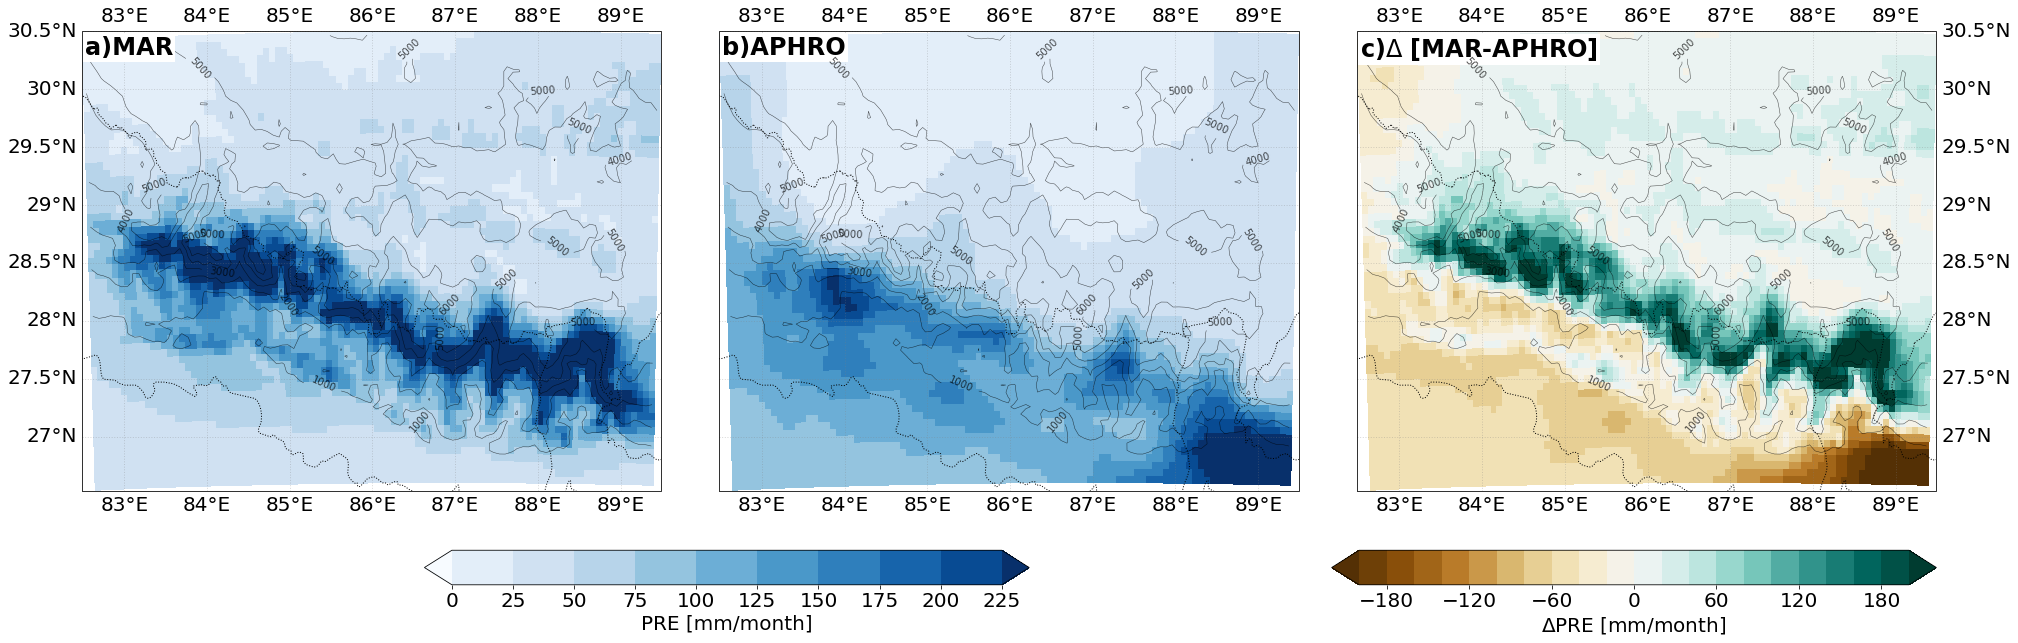

In [28]:

# ---- Color scales ----
clevs_mod = np.arange(0, 250, 25)
clevs_bias = np.arange(-200, 220, 20)

cmap_mod = plt.get_cmap('Blues')
cmap_bias = plt.get_cmap('BrBG')

norm_mod = mcolors.BoundaryNorm(boundaries=clevs_mod, ncolors=cmap_mod.N, extend="both")
norm_bias = mcolors.BoundaryNorm(boundaries=clevs_bias, ncolors=cmap_bias.N, extend="both")

# ---- Create figure and axes ----
fig, axes = plt.subplots(
    1, 3, figsize=(28, 12),
    subplot_kw={'projection': ccrs.PlateCarree()}
)

# ---- Plot configurations ----
#titles = ["(a) MAR-MARgrid", "(b)APHRO-MARgrid", "(c) $\Delta$(MAR - APHRO)"]

fields = [annual_clim, annual_clim_obs, annual_clim - annual_clim_obs]
cmaps = [cmap_mod, cmap_mod, cmap_bias]
norms = [norm_mod, norm_mod, norm_bias]

# ---- Loop through subplots ----
for i, ax in enumerate(axes):
    if i==2:
        im2 = ax.pcolormesh(LONS, LATS, fields[i],
                       transform=ccrs.PlateCarree(),
                       cmap=cmaps[i], norm=norms[i], shading='auto')
    else:
        im = ax.pcolormesh(LONS, LATS, fields[i],
                       transform=ccrs.PlateCarree(),
                       cmap=cmaps[i], norm=norms[i], shading='auto')

    ax.add_feature(cfeature.COASTLINE)
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    ax.set_aspect(1.4)
    #ax.set_title(titles[i], fontsize=18)

    # SH contours (elevation)
    SH1 = ax.contour(LONS, LATS, dsSH,
                     levels=[1000,2000,3000,4000,5000,6000,7000],
                     colors="k", linewidths=0.5, alpha=0.7,
                     transform=ccrs.PlateCarree())
    ax.clabel(SH1, inline=True, fontsize=10, fmt="%d")

    # Zero isoline
    iso = ax.contour(LONS, LATS, annual_clim,
                     levels=[0], colors="blue", linewidths=2.0, alpha=1.0,
                     transform=ccrs.PlateCarree())

axs_f = axes.flatten()

for i, ax in enumerate(axs_f):

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=1,
        color="gray",
        alpha=0.3,
        linestyle=":"
    )

    gl.xlabel_style = {"size": 20}
    gl.ylabel_style = {"size": 20}

    # Remove labels on all sides first
    gl.top_labels = False
    gl.bottom_labels = False
    gl.left_labels = False
    gl.right_labels = False

    # Apply desired labeling logic
    if i in [0, 3, 6]:           # left column
        gl.top_labels = True
        gl.bottom_labels = True
        gl.left_labels = True

    elif i in [1, 4, 7]:         # middle column
        gl.top_labels = True
        gl.bottom_labels = True

    elif i in [2, 5, 8]:         # right column
        gl.top_labels = True
        gl.bottom_labels = True
        gl.right_labels = True
        
letterList = ["a)MAR", "b)APHRO", "c)$\Delta$ [MAR-APHRO]"]

for i, ax in enumerate(axes.flatten()):
    ax.text(
        0.005, 0.99,            # position inside axes (left, top)
        letterList[i],
        transform=ax.transAxes,
        fontsize=24,
        fontweight='bold',
        va='top',
        ha='left',
        bbox=dict(facecolor='white', edgecolor='none', alpha=1.0, pad=2)
    )

# ---- Colorbars ----
# Shared colorbar for MAR/OBS (first two)
cbar_loc_ax1 = fig.add_axes([0.2, 0.12, 0.3, 0.04])##[x0, y0, width, height]
cbar_ax1= fig.colorbar(im, cax=cbar_loc_ax1, orientation="horizontal")
cbar_ax1.set_label("PRE [mm/month]", fontsize=20)
cbar_ax1.ax.tick_params(labelsize=20)

# Separate colorbar for bias (last one)
cbar_loc_ax2 = fig.add_axes([0.65, 0.12, 0.3, 0.04])
cbar_ax2= fig.colorbar(im2, cax=cbar_loc_ax2, orientation="horizontal")
cbar_ax2.set_label("$\Delta$PRE [mm/month]", fontsize=20)
cbar_ax2.ax.tick_params(labelsize=20)

# ---- Layout adjustments ----
#fig.subplots_adjust(left=0.02, right=0.98, top=0.92, bottom=0.15, wspace=0.2,hspace=0.2)
plt.subplots_adjust(left=0.03, right=0.95, top=0.98, bottom=0.01,
                    wspace=0.1, hspace=0.25)


# ---- Save ----
plotsDir="/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/"
plotname="FIGS1_pre.aphro_clim_bias_nepal_MARgrid"
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight")
#plt.savefig(plotsDir + plotname + '.eps', format='eps', dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")
plt.show()


In [6]:
###
###

In [30]:
domain='GRi';domainM='GRp';spin='spin2';var='PRE';units='mm/month';
nx=10;ny=10

sourceData=f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout/{domain}/spin2/work/monthly/'
model1='MAR'
ds_RF_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'+
                            'RF_mon_MARv3.14_ER5_spin2_'+domainM+'_1950-2024.nc')['RF']
ds_RF = ds_RF_raw.rename({'TIME': 'time'})
###
ds_SF_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'+
                            'SF_mon_MARv3.14_ER5_spin2_'+domainM+'_1950-2024.nc')['SF']
ds_SF = ds_SF_raw.rename({'TIME': 'time'})
ds_TF=ds_RF+ds_SF

ds1=ds_TF[:,ny:-ny,nx:-nx].sel(time=slice(str(iyr), str(fyr)))
field1=ds1

ds_grM= xr.open_dataset(f'/home/santolam/NST.2014.01.01.00.{domain}.nc')
LONS=ds_grM.LON[ny:-ny,nx:-nx].values
LATS=ds_grM.LAT[ny:-ny,nx:-nx].values
dsSH=ds_grM.SH[ny:-ny,nx:-nx]
dsICE=ds_grM.ICE[ny:-ny,nx:-nx]

latS=LATS.min(); latN=LATS.max()
lonW=LONS.min(); lonE=LONS.max()

rmon_List=[1,2,3,4,5,6,7,8,9,10,11,12]
vals_List=[]; #anoms_List=[];anoms_detrend_List=[]
for rmon in rmon_List:
    vals,anoms=climb.monthly_selection(field1,rmon,iyr,fyr)
    vals_List.append(vals)
climList=[];
for elem in vals_List:
    clim=elem.mean('time');
    climList.append(clim); 
arr = np.asarray(climList)  # turns a list into a numpy array
annual_clim= arr.mean(axis=0)

In [33]:
model3='aphro'
res3=str('0.25°x0.25°')

fileName3=f'APHRO_mon_MA_025deg_V1101_EXR1.1951-2015_remapMAR_{domain}_7kmx7km.nc'
ds3 = xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/aphro/monthly/'
                      +fileName3,decode_times=False)['precip']
start_date = pd.Timestamp('1951-01-01')
# Create new time index
nmonths = ds3.time.size
time_new = pd.date_range(start=start_date, periods=nmonths, freq='MS')  # 'MS' = Month Start
# Replace time in dataset
ds3['time'] = time_new
#ds3=dom.reversing_lat(ds3)
#ds3=ds3.rename({'latitude':'lat','longitude':'lon'})
field3_mm_day=ds3#.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field3_mm_day=field3_mm_day.sel(time=slice(str(iyr),str(fyr)))

# Convert mm/day to mm/month
days_in_month = field3_mm_day['time'].dt.days_in_month
field3= field3_mm_day * days_in_month

field3.shape

#ds3_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+'gmted_on_aphro.nc')['elevation']
#ds3_SH=ds3_SH_raw.rename({'latitude':'lat','longitude':'lon'})
#ds3_SH=dom.reversing_lat(ds3_SH)
field3_SH=dsSH#ds3_SH#.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field3_SH.shape
field_obs=field3[:,ny:-ny,nx:-nx]
field_obs.shape

vals_List_obs=[]; 
for rmon in rmon_List:
    vals_obs,anoms_obs=climb.monthly_selection(field_obs,rmon,iyr,fyr)
    vals_List_obs.append(vals_obs)
climList_obs=[];
for elem_obs in vals_List_obs:
    clim_obs=elem_obs.mean('time')
    climList_obs.append(clim_obs);
arr_obs = np.asarray(climList_obs)  # turns a list into a numpy array
annual_clim_obs= arr_obs.mean(axis=0)

/home/santolam/.conda/envs/mariaenv/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1666: UserWarning: No contour levels were found within the data range.
  result = matplotlib.axes.Axes.contour(self, *args, **kwargs)
/home/santolam/.conda/envs/mariaenv/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1666: UserWarning: No contour levels were found within the data range.
  result = matplotlib.axes.Axes.contour(self, *args, **kwargs)
/home/santolam/.conda/envs/mariaenv/lib/python3.9/site-packages/cartopy/mpl/geoaxes.py:1666: UserWarning: No contour levels were found within the data range.
  result = matplotlib.axes.Axes.contour(self, *args, **kwargs)


Saved: /home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/FIGS2_pre.aphro_clim_bias_pamir_MARgrid.png


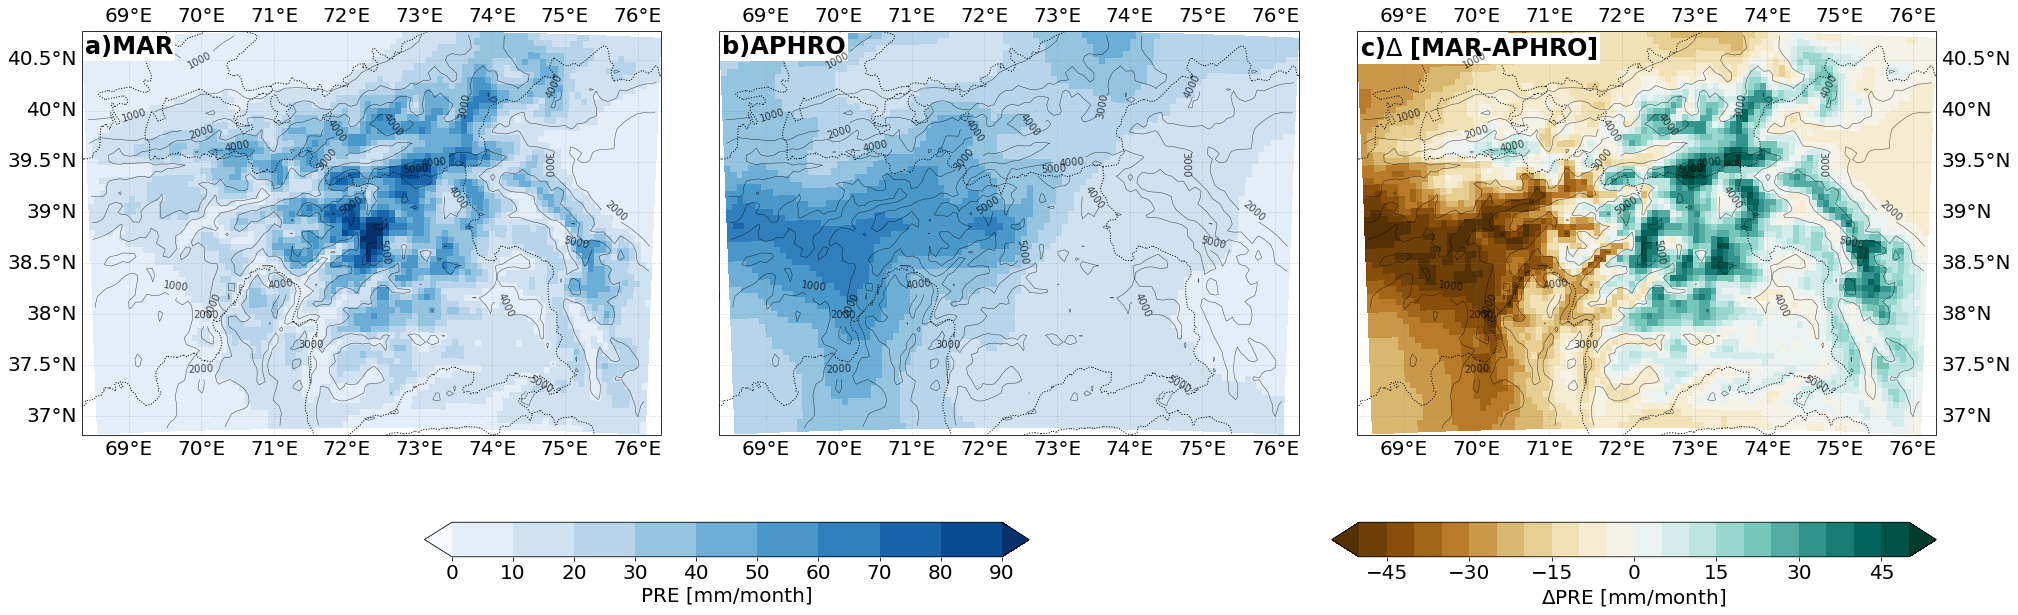

In [35]:

# ---- Color scales ----
clevs_mod = np.arange(0, 100, 10)
clevs_bias = np.arange(-50, 55, 5)

cmap_mod = plt.get_cmap('Blues')
cmap_bias = plt.get_cmap('BrBG')

norm_mod = mcolors.BoundaryNorm(boundaries=clevs_mod, ncolors=cmap_mod.N, extend="both")
norm_bias = mcolors.BoundaryNorm(boundaries=clevs_bias, ncolors=cmap_bias.N, extend="both")

# ---- Create figure and axes ----
fig, axes = plt.subplots(
    1, 3, figsize=(28, 12),
    subplot_kw={'projection': ccrs.PlateCarree()}
)

# ---- Plot configurations ----
#titles = ["(a) MAR-MARgrid", "(b)APHRO-MARgrid", "(c) $\Delta$(MAR - APHRO)"]

fields = [annual_clim, annual_clim_obs, annual_clim - annual_clim_obs]
cmaps = [cmap_mod, cmap_mod, cmap_bias]
norms = [norm_mod, norm_mod, norm_bias]

# ---- Loop through subplots ----
for i, ax in enumerate(axes):
    if i==2:
        im2 = ax.pcolormesh(LONS, LATS, fields[i],
                       transform=ccrs.PlateCarree(),
                       cmap=cmaps[i], norm=norms[i], shading='auto')
    else:
        im = ax.pcolormesh(LONS, LATS, fields[i],
                       transform=ccrs.PlateCarree(),
                       cmap=cmaps[i], norm=norms[i], shading='auto')

    ax.add_feature(cfeature.COASTLINE)
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    ax.set_aspect(1.4)
    #ax.set_title(titles[i], fontsize=18)

    # SH contours (elevation)
    SH1 = ax.contour(LONS, LATS, dsSH,
                     levels=[1000,2000,3000,4000,5000,6000,7000],
                     colors="k", linewidths=0.5, alpha=0.7,
                     transform=ccrs.PlateCarree())
    ax.clabel(SH1, inline=True, fontsize=10, fmt="%d")

    # Zero isoline
    iso = ax.contour(LONS, LATS, annual_clim,
                     levels=[0], colors="blue", linewidths=2.0, alpha=1.0,
                     transform=ccrs.PlateCarree())

axs_f = axes.flatten()

for i, ax in enumerate(axs_f):

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=1,
        color="gray",
        alpha=0.3,
        linestyle=":"
    )

    gl.xlabel_style = {"size": 20}
    gl.ylabel_style = {"size": 20}

    # Remove labels on all sides first
    gl.top_labels = False
    gl.bottom_labels = False
    gl.left_labels = False
    gl.right_labels = False

    # Apply desired labeling logic
    if i in [0, 3, 6]:           # left column
        gl.top_labels = True
        gl.bottom_labels = True
        gl.left_labels = True

    elif i in [1, 4, 7]:         # middle column
        gl.top_labels = True
        gl.bottom_labels = True

    elif i in [2, 5, 8]:         # right column
        gl.top_labels = True
        gl.bottom_labels = True
        gl.right_labels = True
        
letterList = ["a)MAR", "b)APHRO", "c)$\Delta$ [MAR-APHRO]"]

for i, ax in enumerate(axes.flatten()):
    ax.text(
        0.005, 0.99,            # position inside axes (left, top)
        letterList[i],
        transform=ax.transAxes,
        fontsize=24,
        fontweight='bold',
        va='top',
        ha='left',
        bbox=dict(facecolor='white', edgecolor='none', alpha=1.0, pad=2)
    )

# ---- Colorbars ----
# Shared colorbar for MAR/OBS (first two)
cbar_loc_ax1 = fig.add_axes([0.2, 0.12, 0.3, 0.04])##[x0, y0, width, height]
cbar_ax1= fig.colorbar(im, cax=cbar_loc_ax1, orientation="horizontal")
cbar_ax1.set_label("PRE [mm/month]", fontsize=20)
cbar_ax1.ax.tick_params(labelsize=20)

# Separate colorbar for bias (last one)
cbar_loc_ax2 = fig.add_axes([0.65, 0.12, 0.3, 0.04])
cbar_ax2= fig.colorbar(im2, cax=cbar_loc_ax2, orientation="horizontal")
cbar_ax2.set_label("$\Delta$PRE [mm/month]", fontsize=20)
cbar_ax2.ax.tick_params(labelsize=20)

# ---- Layout adjustments ----
#fig.subplots_adjust(left=0.02, right=0.98, top=0.92, bottom=0.15, wspace=0.2,hspace=0.2)
plt.subplots_adjust(left=0.03, right=0.95, top=0.98, bottom=0.01,
                    wspace=0.1, hspace=0.25)


# ---- Save ----
plotsDir="/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/"
plotname="FIGS2_pre.aphro_clim_bias_pamir_MARgrid"
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight")
#plt.savefig(plotsDir + plotname + '.eps', format='eps', dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")
plt.show()
